# 8-5. 로그변환 진단 (잔차 정규성 비교)

통계모델은 대개 오차에 정규분포를 가정하므로, 로그변환으로 예측오차가 정규에 가까워져 성능이 좋아지는지 확인한다.

방법: (1) 예측오차 z 정규성 진단, (2) 로그 스케일에서 9개 (d,p)를 돌려 원 스케일로 역변환해 채점, (3) 두 결과 비교. 원 스케일 비교 대상은 `8-4`, 모델 함수는 `8-2`와 같다.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from arch.univariate import ARX, ZeroMean, GARCH
from scipy import stats
from scipy.optimize import minimize

H, MIN_TRAIN, INITIAL_CALIB, ALPHA = 4, 20, 15, 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
XI_MEAN, XI_VAR, MAX_PHI = -1.2704, np.pi ** 2 / 2, 0.97
MODEL_NAMES = ["AR단독", "GARCH동시", "SV동시"]

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals = raw[["quarter", "X3_l1"]].dropna()["X3_l1"].values.astype(float)
var_std = vals.std()
scored_origins = list(range(MIN_TRAIN, len(vals) - H + 1))[INITIAL_CALIB:]
print(f"채점 origin {len(scored_origins)}개")


채점 origin 22개


## 1. 수정된 세 모델 함수

`8-2`와 같은 코드다(노트북 하나로 완결되게 다시 정의했다).


In [2]:
def difference(values, d):
    x = np.asarray(values, dtype=float)
    hist = []
    for _ in range(d):
        hist.append(x.copy())
        x = np.diff(x)
    return x, hist


def undiff_mean(diff_fc, hist, d):
    fc = np.asarray(diff_fc, dtype=float)
    for i in reversed(range(d)):
        fc = hist[i][-1] + np.cumsum(fc)
    return fc


def is_ar_stable(ar_coefs):
    p = len(ar_coefs)
    if p == 0:
        return True
    companion = np.zeros((p, p))
    companion[0, :] = ar_coefs
    if p > 1:
        companion[1:, :-1] = np.eye(p - 1)
    return np.max(np.abs(np.linalg.eigvals(companion))) < 0.999


def level_sigma(ar_coefs, d, innov_var):
    # ARIMA(p,d,0)의 h단계 수준 예측오차 표준편차: 오차 eps_(t+i)가 psi_(h-i)배로 쌓인다
    # (psi = AR 충격반응을 d번 누적합). innov_var[i] = (i+1)단계 오차분산 예측.
    p = len(ar_coefs)
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(ar_coefs[k] * psi[j - 1 - k] for k in range(min(p, j)))
    for _ in range(d):
        psi = np.cumsum(psi)
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def sv_residuals(y, ar):
    p = len(ar)
    return np.array([y[t] - sum(ar[i] * y[t - 1 - i] for i in range(p)) for t in range(p, len(y))])


def joint_sv_negloglik(params, y, p):
    ar, phi, s2 = params[:p], MAX_PHI * np.tanh(params[p]), np.exp(params[p + 1]) ** 2
    if not is_ar_stable(ar):
        return 1e10
    z = np.log(sv_residuals(y, ar) ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, s2)


def ar_forecast(train, d, p):
    m = pm.ARIMA(order=(p, d, 0), with_intercept=False, suppress_warnings=True).fit(train)
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    par = dict(zip(m.arima_res_.model.param_names, m.arima_res_.params))
    ar = [par[f"ar.L{k}"] for k in range(1, p + 1)]
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z), {"ar1": ar[0] if p else np.nan}


def garch_forecast(train, d, p):
    diff_train, hist = difference(train, d)
    if len(diff_train) <= p + 3:
        return None
    am = ZeroMean(diff_train, rescale=False) if p == 0 else ARX(diff_train, lags=p, constant=False, rescale=False)
    am.volatility = GARCH(p=1, q=1)
    try:
        res = am.fit(disp="off")
    except Exception:
        return None
    f = res.forecast(horizon=H, reindex=False)
    ar = [res.params[f"y[{k}]"] for k in range(1, p + 1)]
    fc = undiff_mean(f.mean.values[-1], hist, d)
    sig = level_sigma(ar, d, f.residual_variance.values[-1])
    return fc, sig, {"ar1": ar[0] if p else np.nan, "omega": res.params["omega"], "alpha": res.params["alpha[1]"], "beta": res.params["beta[1]"]}


def sv_forecast(train, d, p):
    y, hist = difference(train, d)
    if len(y) <= p + 3:
        return None
    res = minimize(joint_sv_negloglik, [0.0] * p + [1.5, np.log(0.3)], args=(y, p), method="Nelder-Mead", options={"maxiter": 3000})
    if not is_ar_stable(res.x[:p]) or res.fun >= 1e9:
        return None
    ar, phi, s2 = res.x[:p], MAX_PHI * np.tanh(res.x[p]), np.exp(res.x[p + 1]) ** 2
    z = np.log(sv_residuals(y, ar) ** 2 + 1e-8)
    zm = z.mean()
    P, h = s2 / (1 - phi ** 2), 0.0
    for x in z - zm:
        K = P / (P + XI_VAR)
        hf, Pf = h + K * (x - h), P * (1 - K)
        h, P = phi * hf, phi ** 2 * Pf + s2
    past = list(y[-p:]) if p else []
    mean_diff = []
    for _ in range(H):
        pred = sum(ar[i] * past[-1 - i] for i in range(p))
        mean_diff.append(pred)
        past.append(pred)
    v = [np.exp(zm - XI_MEAN + phi ** k * hf + (phi ** (2 * k) * Pf + s2 * sum(phi ** (2 * j) for j in range(k))) / 2)
         for k in range(1, H + 1)]
    return undiff_mean(mean_diff, hist, d), level_sigma(ar, d, v), {"ar1": ar[0] if p else np.nan, "phi_logvol": phi, "sigma_eta": np.sqrt(s2)}


FORECASTERS = {"AR단독": ar_forecast, "GARCH동시": garch_forecast, "SV동시": sv_forecast}


def run(d, p):
    rows, infos = [], []
    for origin in scored_origins:
        train, actual = vals[:origin], vals[origin:origin + H]
        for name, fn in FORECASTERS.items():
            try:
                out = fn(train, d, p)
            except Exception:
                out = None
            if out is None:
                continue
            fc, sig, info = out
            infos.append({"d": d, "p": p, "모델": name, "origin": origin, **info})
            for h in range(H):
                rows.append({"d": d, "p": p, "모델": name, "origin": origin, "h": h + 1, "fc": fc[h],
                             "sigma": max(sig[h], 1e-6), "actual": actual[h]})
    return pd.DataFrame(rows), pd.DataFrame(infos)


def add_scores(df):
    df = df.copy()
    df["z"] = (df["actual"] - df["fc"]) / df["sigma"]
    df["cov"] = (df["z"].abs() <= Z) * 100.0
    df["mse"] = ((df["actual"] - df["fc"]) / var_std) ** 2
    df["crps"] = ps.crps_gaussian(df["actual"], mu=df["fc"], sig=df["sigma"]) / var_std
    return df


def summarize(df, keys=("모델",)):
    return df.groupby(list(keys)).agg(커버리지=("cov", "mean"), MSE=("mse", "mean"), CRPS=("crps", "mean")).round(3)


## 2. 로그 스케일 도구

`100·log(y)`에 세 모델을 적용하고 (μ, σ)를 100으로 나눠 원 스케일로 역변환해 채점한다. 커버리지는 `exp(μ±Zσ)`, MSE는 평균 `exp(μ+σ²/2)`(중앙값 `exp(μ)`는 참고), CRPS는 로그정규 닫힌형 공식이다.

In [3]:
LOG = 100 * np.log(vals)
D_CANDIDATES, P_CANDIDATES = [0, 1, 2], [0, 1, 2]


def run_log(d, p):
    rows = []
    for origin in scored_origins:
        train, actual = LOG[:origin], vals[origin:origin + H]
        for name, fn in FORECASTERS.items():
            try:
                out = fn(train, d, p)
            except Exception:
                out = None
            if out is None:
                continue
            fc, sig, _ = out
            for h in range(H):
                rows.append({"d": d, "p": p, "모델": name, "origin": origin, "h": h + 1, "fc": fc[h],
                             "sigma": max(sig[h], 1e-6), "actual": actual[h]})
    return pd.DataFrame(rows)


def add_log_scores(df):
    df = df.copy()
    mu, s, a = df["fc"] / 100, df["sigma"] / 100, df["actual"]
    df["z"] = (np.log(a) - mu) / s
    lo, hi = np.exp(mu - Z * s), np.exp(mu + Z * s)
    df["cov"] = ((a >= lo) & (a <= hi)) * 100.0
    m = np.exp(mu + s ** 2 / 2)
    crps = a * (2 * stats.norm.cdf(df["z"]) - 1) - 2 * m * (stats.norm.cdf(df["z"] - s) + stats.norm.cdf(s / np.sqrt(2)) - 1)
    for col, val in [("mse", ((a - m) / var_std) ** 2), ("mse_med", ((a - np.exp(mu)) / var_std) ** 2), ("crps", crps / var_std)]:
        df[col] = np.where(np.isfinite(val), val, np.inf)
    return df


## 3. 로그 스케일 그리드 -- 원 스케일(`8-4`)과 비교

9개 (d,p) x 세 모델 x 22개 origin을 로그 스케일에서 다시 돌려 캐시에 저장하고, 원 스케일 결과(`8-4` 캐시)와 나란히 본다.


In [4]:
CACHE_PATH = "../cache/cache_85_fixed_log_grid_df.pkl"
if os.path.exists(CACHE_PATH):
    log_grid = pd.read_pickle(CACHE_PATH)
    print(f"캐시에서 로드: {len(log_grid)}행 (재계산 스킵)")
else:
    log_grid = pd.concat([add_log_scores(run_log(d, p)) for d in D_CANDIDATES for p in P_CANDIDATES], ignore_index=True)
    os.makedirs(os.path.dirname(CACHE_PATH), exist_ok=True)
    log_grid.to_pickle(CACHE_PATH)
    print(f"새로 계산 후 캐시 저장: {len(log_grid)}행")

orig_grid = pd.read_pickle("../cache/cache_84_fixed_dp_grid_df.pkl")
keys = ["d", "p", "모델"]
o_sum = summarize(orig_grid, keys)
l_sum = log_grid.groupby(keys).agg(커버리지=("cov", "mean"), MSE=("mse", "mean"), CRPS=("crps", "mean")).round(3)
l_sum["MSE(중앙값)"] = log_grid.groupby(keys)["mse_med"].mean().round(3)
display(o_sum.join(l_sum, lsuffix="_원", rsuffix="_로그"))


캐시에서 로드: 2376행 (재계산 스킵)


커버리지_원   MSE_원  CRPS_원  커버리지_로그         MSE_로그       CRPS_로그  \
d p 모델                                                                       
0 0 AR단독      63.636   8.806   1.849  100.000   5.645622e+11  1.042000e+01   
    GARCH동시   88.636   8.806   1.721  100.000   2.750222e+14  2.055000e+01   
    SV동시     100.000   8.806   1.730  100.000   1.816502e+54  1.454424e+11   
  1 AR단독      59.091   1.065   0.579   72.727   1.073000e+00  5.790000e-01   
    GARCH동시   72.727   1.075   0.588   75.000   1.261000e+00  6.280000e-01   
    SV동시      96.591   8.599   1.633  100.000   2.881153e+41  3.468137e+07   
  2 AR단독      63.636   1.158   0.593   77.273   1.646000e+00  6.480000e-01   
    GARCH동시   73.864   1.130   0.595   72.727   2.758000e+00  6.950000e-01   
    SV동시      96.591  12.071   1.930  100.000  1.004968e+241  3.424640e+10   
1 0 AR단독      59.091   1.040   0.579   72.727   1.089000e+00  5.810000e-01   
    GARCH동시   72.727   1.040   0.577   77.273   1.134000e+00  6.080000e-01   
    SV동시      70.455   1.040   0.568   78.409   1.129000e+00  5.840000e-01   
  1 AR단독      65.909   1.128   0.593   78.409   1.902000e+00  6.680000e-01   
    GARCH동시   73.864   1.080   0.582   73.864   2.412000e+00  6.780000e-01   
    SV동시      64.773   1.052   0.578   73.864   1.102000e+00  5.900000e-01   
  2 AR단독      68.182   1.076   0.577   71.591   1.996000e+00  6.950000e-01   
    GARCH동시   71.591   1.118   0.601   73.864   3.152000e+00  7.160000e-01   
    SV동시      64.773   1.051   0.580   72.727   1.097000e+00  5.970000e-01   
2 0 AR단독      63.636   2.625   0.891   72.727   9.662500e+01  1.628000e+00   
    GARCH동시   81.818   2.625   0.867   79.545   1.849806e+04  2.678000e+00   
    SV동시      69.318   2.625   0.895   82.955   2.027590e+02  1.744000e+00   
  1 AR단독      59.091   2.445   0.873   65.909   3.412100e+01  1.397000e+00   
    GARCH동시   69.318   2.435   0.844   77.273   8.708220e+02  1.847000e+00   
    SV동시      56.818   2.551   0.898   67.045   1.009350e+02  1.621000e+00   
  2 AR단독      55.682   2.205   0.839   65.909   1.882500e+01  1.252000e+00   
    GARCH동시   68.182   2.264   0.832   78.409   6.606350e+02  1.782000e+00   
    SV동시      57.955   2.723   0.928   63.636   5.572500e+01  1.684000e+00   

             MSE(중앙값)  
d p 모델                 
0 0 AR단독        8.787  
    GARCH동시     8.787  
    SV동시        8.787  
  1 AR단독        1.039  
    GARCH동시     1.087  
    SV동시        8.753  
  2 AR단독        1.232  
    GARCH동시     1.135  
    SV동시        8.771  
1 0 AR단독        1.040  
    GARCH동시     1.040  
    SV동시        1.040  
  1 AR단독        1.326  
    GARCH동시     1.052  
    SV동시        1.053  
  2 AR단독        1.401  
    GARCH동시     1.316  
    SV동시        1.057  
2 0 AR단독       25.393  
    GARCH동시    25.393  
    SV동시       25.393  
  1 AR단독       13.359  
    GARCH동시    13.688  
    SV동시       18.594  
  2 AR단독        8.697  
    GARCH동시    12.303  
    SV동시       23.894

## 4. 순위 합산 -- (d,p) 조합별 종합 순위


In [5]:
def rank_sum(summary_df):
    parts = []
    for m in MODEL_NAMES:
        sub = summary_df.xs(m, level="모델")
        parts.append(pd.DataFrame({"커버리지순위": (sub["커버리지"] - 90).abs().rank(), "MSE순위": sub["MSE"].rank(), "CRPS순위": sub["CRPS"].rank()}))
    rs = sum(parts)
    rs["합계"] = rs.sum(axis=1)
    return rs.sort_values("합계")


print("원 스케일 (8-4와 동일):")
display(rank_sum(o_sum))
print("\n로그 스케일:")
display(rank_sum(l_sum[["커버리지", "MSE", "CRPS"]]))


원 스케일 (8-4와 동일):


커버리지순위  MSE순위  CRPS순위    합계
d p                             
1 0    16.5    3.0     4.5  24.0
  1    12.0   10.0     8.5  30.5
  2    14.5    9.0     9.0  32.5
0 1    14.0   11.0    12.5  37.5
  2     9.0   19.0    17.5  45.5
2 0    11.0   21.0    20.0  52.0
0 0     8.0   26.0    26.0  60.0
2 1    24.0   18.0    19.0  61.0
  2    26.0   18.0    18.0  62.0


로그 스케일:


커버리지순위  MSE순위  CRPS순위    합계
d p                             
1 0    14.5    6.0     4.0  24.5
  1    15.5    9.0     9.0  33.5
0 1    14.0   10.0    10.0  34.0
1 2    21.5   11.0    13.0  45.5
0 2    15.0   16.0    15.0  46.0
2 0     8.0   22.0    22.0  52.0
  2    20.5   16.0    17.0  53.5
0 0     5.0   26.0    27.0  58.0
2 1    21.0   19.0    18.0  58.0

## 5. 예측오차(z) 진단 -- 정규성과 σ 배율 (d=1, p=1)

로그변환의 효과는 **out-of-sample 예측오차 z**로 본다. `z = (실측 - 예측) / σ`(로그 스케일은 `(ln 실측 - μ) / s`), 22 origin x h=1~4 = 88개(겹침)다.

**σ와 σ 배율**
- **σ**: 모델이 내는 예측오차의 표준편차다. 90% 구간은 `예측 ± 1.645σ`(1.645는 정규분포에서 양쪽 90%를 덮는 상수)다.
- **z 표준편차 = 1이 목표**: 모델의 주장이 맞으면 z는 N(0,1)이다. 1보다 크면 σ 과소(구간이 좁아 커버리지 90% 미만), 작으면 σ 과대다.
- **σ 배율** = |z|의 90분위값 ÷ 1.645. 90% 구간을 맞추려면 σ를 몇 배로 키워야 하는지를 나타낸다.
  - **1보다 크다 = σ 과소**: 모델이 실제보다 자신만만하다. 구간이 좁아 커버리지가 90% 미만이다(예: 1.8이면 σ를 약 1.8배 키워야 맞는다).
  - **1보다 작다 = σ 과대**: 구간이 불필요하게 넓다. 커버리지는 90%를 넘고 CRPS는 손해를 본다.
  - **1 = 적정**.
- 88개(겹침)라 1에서 조금 벗어난 값은 우연일 수 있다.

**JB p (Jarque-Bera 검정)**: 왜도와 초과첨도로 "z가 정규분포다"를 검정한다. **0.05 미만이면 정규분포가 아니라는 증거**이고, 크면 "그런 증거가 없다"는 뜻이지 정규분포임을 증명하지는 않는다. 표본이 작아 검정력이 낮고 극단값에 민감하다.

**극단값 2개 제외**: |z|가 가장 큰 2개를 뺀 뒤 다시 계산한 JB p다(몸통은 정규인데 소수의 큰 값 때문에 기각되는지 확인).

In [6]:
def z_summary(g):
    z = g["z"].values
    a = np.abs(z)
    keep = np.argsort(a)[:-2]
    return pd.Series({"z 표준편차": z.std(), "|z| 중앙값": np.median(a), "커버리지(%)": 100 * np.mean(a <= Z), "σ 배율": np.quantile(a, 0.9) / Z,
                      "왜도": stats.skew(z), "초과첨도": stats.kurtosis(z), "JB p(전체)": stats.jarque_bera(z).pvalue,
                      "JB p(극단값 2개 제외)": stats.jarque_bera(z[keep]).pvalue})


z11 = pd.concat({"원 스케일": orig_grid[(orig_grid["d"] == 1) & (orig_grid["p"] == 1)],
                 "로그 스케일": log_grid[(log_grid["d"] == 1) & (log_grid["p"] == 1)]}, names=["스케일"]).reset_index(level=0)
display(z11.groupby(["스케일", "모델"]).apply(z_summary).round(3))
print("h별 z 표준편차:")
display(z11.groupby(["스케일", "모델", "h"])["z"].std().unstack("h").round(2))


z 표준편차  |z| 중앙값  커버리지(%)   σ 배율     왜도   초과첨도  JB p(전체)  \
스케일    모델                                                                 
로그 스케일 AR단독      1.384    0.603   78.409  1.354  1.045  1.046     0.000   
       GARCH동시   1.516    0.430   73.864  1.722  0.309  1.275     0.025   
       SV동시      1.499    0.667   73.864  1.565 -0.008  0.352     0.796   
원 스케일  AR단독      2.104    1.215   65.909  1.802  1.100  1.269     0.000   
       GARCH동시   1.988    0.782   73.864  2.109  0.867  1.983     0.000   
       SV동시      2.106    1.027   64.773  2.048  1.039  1.080     0.000   

                JB p(극단값 2개 제외)  
스케일    모델                        
로그 스케일 AR단독               0.009  
       GARCH동시            0.132  
       SV동시               0.609  
원 스케일  AR단독               0.001  
       GARCH동시            0.001  
       SV동시               0.001

h별 z 표준편차:


h                  1     2     3     4
스케일    모델                             
로그 스케일 AR단독     1.60  1.48  1.35  1.20
       GARCH동시  1.72  1.63  1.46  1.37
       SV동시     1.26  1.55  1.65  1.64
원 스케일  AR단독     2.11  2.19  2.18  2.11
       GARCH동시  2.06  2.10  2.03  1.94
       SV동시     1.67  2.12  2.33  2.41

### z 분포 비교 (그림)

위 줄은 z 히스토그램과 N(0,1)(검정 점선), 아래 줄은 정규 Q-Q 플롯이다. 원 스케일(주황)과 로그 스케일(파랑)을 겹쳤다.

**Q-Q 플롯 읽는 법**: x축은 정규분포라면 그 순번에 와야 할 값, y축은 실제 z(작은 값부터)다.
- 점선(y=x)에 붙을수록 정규분포다.
- 점선보다 가파르면 실제 오차가 σ보다 크다(σ 과소).
- 오른쪽 끝이 위로 치솟으면 큰 양의 오차(오른쪽 꼬리)가 두껍다.

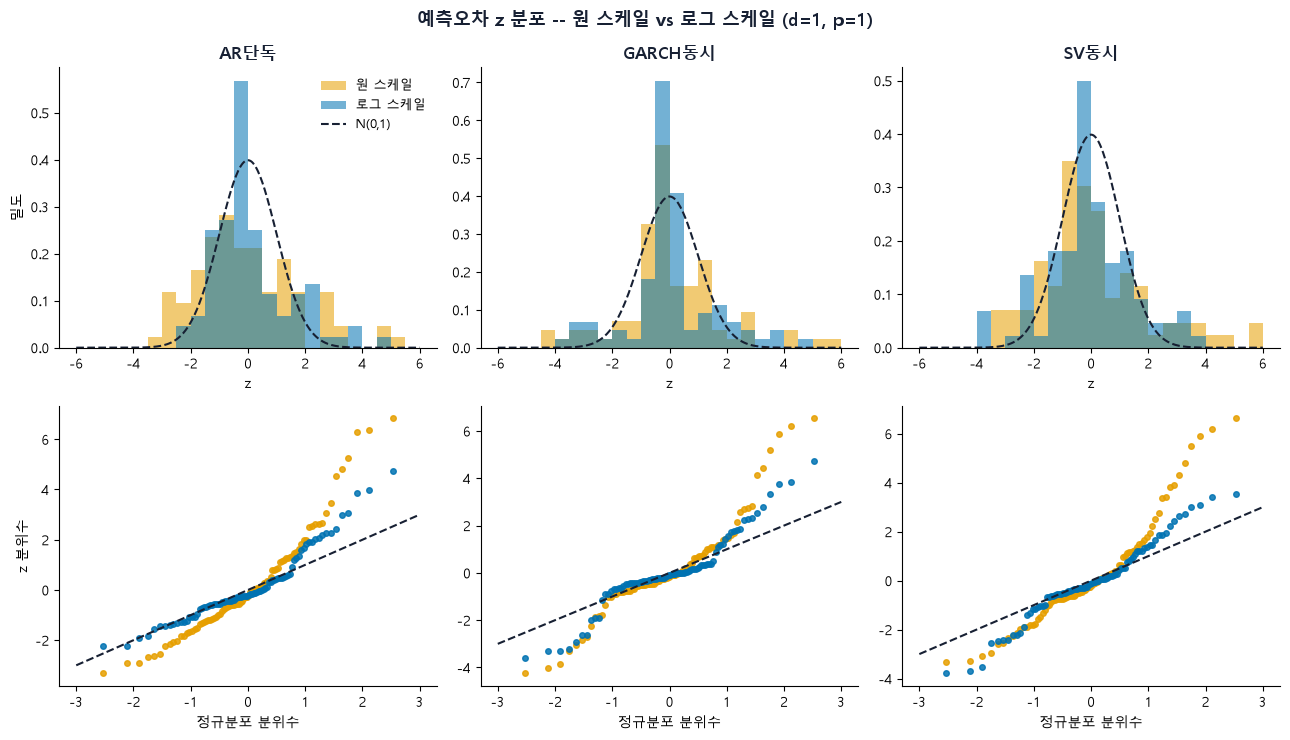

In [7]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

sc_colors = {"원 스케일": "#E69F00", "로그 스케일": "#0072B2"}
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
grid_x = np.linspace(-6, 6, 300)
for k, m in enumerate(MODEL_NAMES):
    for sc, color in sc_colors.items():
        z = np.sort(z11[(z11["스케일"] == sc) & (z11["모델"] == m)]["z"].values)
        axes[0, k].hist(z, bins=np.linspace(-6, 6, 25), density=True, alpha=0.55, color=color, label=sc)
        q = stats.norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))
        axes[1, k].plot(q, z, "o", ms=4, color=color, alpha=0.85, label=sc)
    axes[0, k].plot(grid_x, stats.norm.pdf(grid_x), "--", color="#172033", linewidth=1.5, label="N(0,1)")
    axes[0, k].set_title(m, fontsize=12, fontweight="bold", color="#172033")
    axes[0, k].set_xlabel("z")
    axes[1, k].plot([-3, 3], [-3, 3], "--", color="#172033", linewidth=1.5)
    axes[1, k].set_xlabel("정규분포 분위수")
    axes[1, k].set_ylabel("z 분위수" if k == 0 else "")
    for ax in axes[:, k]:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
axes[0, 0].set_ylabel("밀도")
axes[0, 0].legend(frameon=False, fontsize=9)
fig.suptitle("예측오차 z 분포 -- 원 스케일 vs 로그 스케일 (d=1, p=1)", fontsize=13, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()


## 6. 요약 차트 -- d=1, p=1, 원 스케일 vs 로그 스케일


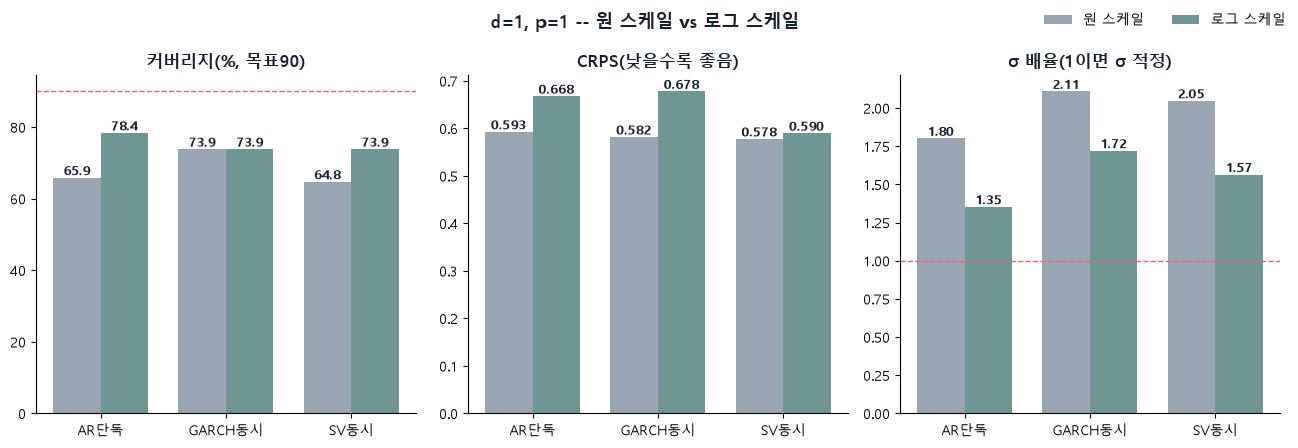

In [8]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

zt = z11.groupby(["스케일", "모델"]).apply(z_summary)
o11, l11 = o_sum.xs((1, 1), level=["d", "p"]), l_sum.xs((1, 1), level=["d", "p"])
panels = [("커버리지(%, 목표90)", o11["커버리지"], l11["커버리지"], "{:.1f}"),
          ("CRPS(낮을수록 좋음)", o11["CRPS"], l11["CRPS"], "{:.3f}"),
          ("σ 배율(1이면 σ 적정)", zt.loc["원 스케일"]["σ 배율"], zt.loc["로그 스케일"]["σ 배율"], "{:.2f}")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
x, w = np.arange(len(MODEL_NAMES)), 0.38
for ax, (title, ov, lv, fmt) in zip(axes, panels):
    b1 = ax.bar(x - w / 2, [ov[m] for m in MODEL_NAMES], w, color="#9AA5B4", label="원 스케일")
    b2 = ax.bar(x + w / 2, [lv[m] for m in MODEL_NAMES], w, color="#6F9692", label="로그 스케일")
    for b in list(b1) + list(b2):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(b.get_height()), ha="center", va="bottom",
                fontsize=9, fontweight="bold", color="#172033")
    if title.startswith("커버리지"):
        ax.axhline(90, color="#EF6461", linestyle="--", linewidth=1)
    if title.startswith("σ"):
        ax.axhline(1, color="#EF6461", linestyle="--", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(MODEL_NAMES)
    ax.set_title(title, fontsize=12, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False, fontsize=10)
fig.suptitle("d=1, p=1 -- 원 스케일 vs 로그 스케일", fontsize=13, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()


## 7. 결론

**로그변환은 채택하지 않는다. 다만 σ 보정 효과는 세 모델 모두에서 나타난다.**

d=1, p=1 (원 스케일 -> 로그 스케일):

| 모델 | 커버리지(%) | MSE (로그: 평균 보정 / 중앙값) | CRPS | σ 배율 |
|---|---|---|---|---|
| AR단독 | 65.9 -> 78.4 | 1.128 -> 1.902 / 1.326 | 0.593 -> 0.668 | 1.80 -> 1.35 |
| GARCH동시 | 73.9 -> 73.9 | 1.080 -> 2.412 / 1.052 | 0.582 -> 0.678 | 2.11 -> 1.72 |
| SV동시 | 64.8 -> 73.9 | 1.052 -> 1.102 / 1.053 | 0.578 -> 0.590 | 2.05 -> 1.57 |

- **정확도는 개선되지 않는다**: CRPS가 세 모델 모두 나빠진다(SV +0.012로 거의 동률, AR +0.075, GARCH +0.096).
- **σ 보정은 좋아진다**: σ 배율이 모두 내려가고 커버리지도 AR단독·SV동시에서 오른다. 그래도 최대 78.4%로 목표 90%에 못 미친다.
- **z의 정규성은 로그 스케일에서 좋아진다**: 원 스케일은 세 모델 모두 JB 기각(극단값 2개 제외해도 기각)이다. 로그 스케일은 SV동시가 기각되지 않고(p=0.80), GARCH동시는 극단값 2개를 빼면 기각되지 않으며(0.03 -> 0.13), AR단독은 여전히 기각된다(왜도 1.04). 다만 88개(겹침)라 검정력이 낮다.
- **정규성이 좋아져도 정확도(CRPS)는 나빠진다.** 로그변환의 이점은 σ 배율·커버리지 정도다.
- **최적 (d,p)는 그대로**: 로그 스케일에서도 p=0 함정을 빼면 d=1,p=1(33.5)이 1위다.
- **판단**: CRPS를 개선하는 모델이 없으므로 미채택이다. 다만 SV동시는 CRPS 차이가 작고(0.578 vs 0.590) 커버리지가 9%p 오르므로 커버리지를 더 중시한다면 후속 후보다(유의성 미검증).